# Oxfordshire House Prices

## How much more do new builds sell for in Oxfordshire (2015–2025), once you account for size, property type, location, time and energy rating?

In [25]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import statsmodels.formula.api as smf



In [4]:
loaded = pd.read_parquet('data/raw/pp_epc_oxfordshire_2015_2025_v2.parquet')

print(loaded.shape)
print(loaded.dtypes)

(114424, 44)
unique_id                                 str
price_paid                              int64
deed_date                      datetime64[ns]
address                                   str
saon                                      str
paon                                      str
street                                    str
locality                                  str
town                                      str
district                                  str
postcode                                  str
property_subtype                          str
new_build                                 str
estate_type                               str
transaction_category                      str
certificate_number                        str
built_form                                str
construction_age_band                     str
current_energy_efficiency               int64
current_energy_rating                     str
energy_consumption_current            float64
extension_count      

In [49]:
cat_a_only = loaded[loaded['transaction_category'] == 'A'].copy()
print(cat_a_only.shape)
cat_a_only['£/m2'] = cat_a_only['price_paid'] / cat_a_only['total_floor_area']

labels = {'F': 'Flat', 'T': 'Terraced', 'S': 'Semi-detached', 'D': 'Detached'}
cat_a_only['property_subtype'] = cat_a_only['property_subtype'].replace(labels)
cat_a_only['district'] = cat_a_only['district'].str.title().str.replace('Of', 'of')

(105046, 44)


In [18]:
grouping = {"A": "A/B", "B": "A/B", "F": "F/G", "G": "F/G"}
rated = cat_a_only.copy()
rated['energy_efficiency_rating_group'] = rated['current_energy_rating'].replace(grouping)
print(rated['energy_efficiency_rating_group'].value_counts())
print(rated.shape)

energy_efficiency_rating_group
D      33813
A/B    29236
C      27692
E      11107
F/G     3198
Name: count, dtype: int64
(105046, 46)


In [19]:
selected_columns = ['price_paid', 'new_build', 'total_floor_area', 'property_subtype', 'district', 'year', 'energy_efficiency_rating_group']
selected = rated[selected_columns].dropna().reset_index(drop=True)
print(selected.info())
print(selected.shape)

<class 'pandas.DataFrame'>
RangeIndex: 105046 entries, 0 to 105045
Data columns (total 7 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   price_paid                      105046 non-null  int64  
 1   new_build                       105046 non-null  str    
 2   total_floor_area                105046 non-null  float64
 3   property_subtype                105046 non-null  str    
 4   district                        105046 non-null  str    
 5   year                            105046 non-null  int32  
 6   energy_efficiency_rating_group  105046 non-null  str    
dtypes: float64(1), int32(1), int64(1), str(4)
memory usage: 7.8 MB
None
(105046, 7)


In [82]:
selected['new_build'].value_counts(normalize=True)

new_build
N    0.81451
Y    0.18549
Name: proportion, dtype: float64

- Initial load 114424 rows
- Cat a only 105046 rows
- Dropped 39 columns not needed
- No nulls in selected fields, so dropna removes no rows
- New builds are 18.6% of 105046

In [24]:
selected['log_price'] = np.log(selected['price_paid'])
selected['log_floor_area'] = np.log(selected['total_floor_area'])
print(selected['log_price'].value_counts(),
selected['log_floor_area'].value_counts())

log_price
12.765688    1407
12.691580    1373
12.611538    1343
12.834681    1273
12.429216    1199
             ... 
12.907778       1
12.835374       1
12.912259       1
12.383838       1
12.736407       1
Name: count, Length: 5542, dtype: int64 log_floor_area
4.369448    1820
4.430817    1515
4.382027    1507
4.343805    1495
4.356709    1484
            ... 
6.317165       1
6.484635       1
6.278521       1
6.194405       1
6.403574       1
Name: count, Length: 513, dtype: int64


<Axes: xlabel='log_price', ylabel='new_build'>

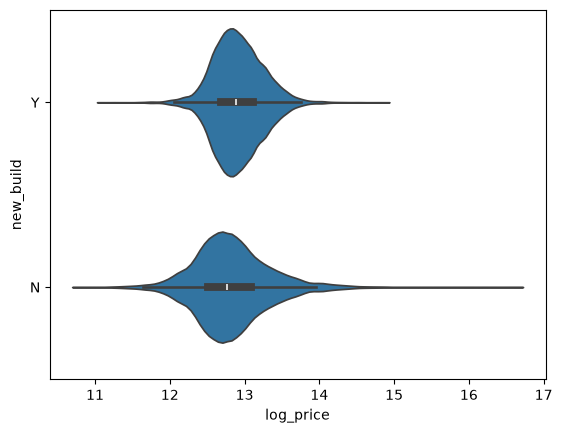

In [29]:
sns.violinplot(selected, x='log_price', y='new_build')

In [ ]:
model = smf.ols('log_price ~ new_build', data=selected).fit(cov_type='HC1') # ols is ordinary least squares (linear) regression. HC1 fits with robust standard errors 'heteroscedasticity' meaning the residuals are not consistent
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     792.8
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          8.62e-174
Time:                        15:18:54   Log-Likelihood:                -73042.
No. Observations:              105046   AIC:                         1.461e+05
Df Residuals:                  105044   BIC:                         1.461e+05
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         12.8221      0.002   7318.

- ols is ordinary least squares (linear) regression. 
- HC1 fits with robust standard errors 'heteroscedasticity' meaning the residuals are not consistent, price variance differs depending on the subcategories
- Used natural log of price and new_build flag (Y/N)

In [47]:
print(f"New builds sold for {100 * (np.exp(0.0843) -1):.1f}% more on average. With a 95% CI of {100 * (np.exp(0.078) -1):.1f} to {100 * (np.exp(0.090) -1):.1f}%")
print(f"Intercept £{(np.exp(12.8221)):,.0f}, the geometric mean of non-new builds")
print("R2=0.005, new build flag explains 0.5% of variance in price")

New builds sold for 8.8% more on average. With a 95% CI of 8.1 to 9.4%
Intercept £370,312, the geometric mean of non-new builds
R2=0.005, new build flag explains 0.5% of variance in price


- New builds sold for 8.8% more on average. With a 95% CI of 8.1 to 9.4%
- Intercept £370,312, the geometric mean of non-new builds
- R2=0.005, new build flag explains 0.5% of variance in price
- skew 0.6, kurtosis 4.9, residuals not normal

Predicting that introducing more variables to control for will reduce the premium associated with the new build flag. As there will be other explanations

In [62]:
cols_to_check = ['new_build', 'property_subtype', 'district', 'year', 'energy_efficiency_rating_group']
for x in cols_to_check:
    print(selected[x].value_counts(normalize=True))

new_build
N    0.81451
Y    0.18549
Name: proportion, dtype: float64
property_subtype
Detached         0.324001
Semi-detached    0.298317
Terraced         0.248225
Flat             0.129458
Name: proportion, dtype: float64
district
Cherwell               0.250738
Vale of White Horse    0.239381
South Oxfordshire      0.221008
West Oxfordshire       0.164490
Oxford                 0.124384
Name: proportion, dtype: float64
year
2021    0.124555
2022    0.100765
2015    0.089504
2016    0.089351
2018    0.089189
2025    0.088114
2017    0.087067
2019    0.086534
2020    0.084439
2024    0.083421
2023    0.077061
Name: proportion, dtype: float64
energy_efficiency_rating_group
D      0.321888
A/B    0.278316
C      0.263618
E      0.105735
F/G    0.030444
Name: proportion, dtype: float64


Used most common values as references

In [68]:
full_model = smf.ols(
    "log_price ~ C(new_build, Treatment(reference='N')) "
    "+ log_floor_area + C(property_subtype, Treatment(reference='Detached')) "
    "+ C(district, Treatment(reference='Cherwell')) "
    "+ C(year, Treatment(reference=2021)) "
    "+ C(energy_efficiency_rating_group, Treatment(reference='D'))", 
    data=selected
).fit(cov_type='HC1')

print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                 1.034e+04
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:22:01   Log-Likelihood:                 1988.8
No. Observations:              105046   AIC:                            -3930.
Df Residuals:                  105022   BIC:                            -3700.
Df Model:                          23                                         
Covariance Type:                  HC1                                         
                                                                            coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------

In [80]:
print(f"New builds sold for {100 * (np.exp(0.0431) -1):.1f}% more on average. With a 95% CI of {100 * (np.exp(0.038) -1):.1f} to {100 * (np.exp(0.048) -1):.1f}%")
print(f"{100*(1.1**0.7917 - 1):.1f}% higher price for 10% more floor area")
print("R2=0.761, these variables could explain 76% of variance in price")

New builds sold for 4.4% more on average. With a 95% CI of 3.9 to 4.9%
7.8% higher price for 10% more floor area
R2=0.761, these variables could explain 76% of variance in price


- Fitting with all the variables
    - New build coefficient was 0.0431 (New builds sold for 4.4% more on average). With a 95% CI of 3.9 to 4.9%
    - R2=0.761, these variables could explain 76% of variance in price
    - 10% more floor area gave a 7.8% higher price (with all other variables held constant). Reasonable
    - All the property_subtypes sold for less than Detached (the reference)
    - All districts sold for more than Cherwell (the reference)
    - Prices were lower before 2021 (the reference) and higher after. But there was a drop 2018 to 2019 and very little change between 2022-2024

In [81]:
full_model_no_epc = smf.ols(
    "log_price ~ C(new_build, Treatment(reference='N')) "
    "+ log_floor_area + C(property_subtype, Treatment(reference='Detached')) "
    "+ C(district, Treatment(reference='Cherwell')) "
    "+ C(year, Treatment(reference=2021)) ", 
    data=selected
).fit(cov_type='HC1')

print(full_model_no_epc.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                 1.229e+04
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:49:28   Log-Likelihood:                 1448.4
No. Observations:              105046   AIC:                            -2857.
Df Residuals:                  105026   BIC:                            -2666.
Df Model:                          19                                         
Covariance Type:                  HC1                                         
                                                                            coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------

- Rerunning the model without the energy efficiency rating brings the coefficient for new_build down to zero.
    - This means that floor_area, property_subtype, district and year fully account for the 8.8% premium on new properties
    - Adding the EPC rating confounds, because it is a surrogate for property age. EPC rating is partly caused by being a new_build, so can be considered a bad control

- Raw model (new build only) - New-build effect = +8.8%
- Adding floor_area, property_subtype, district, year - New-build effect = ca. 0% (-0.5%)
- Adding EPC rating too - New-build effect = +4.4%